# Final model comparison — Improved Highway CNN vs. Standard CNN

**Notebook:** `06_final_model_comparison.ipynb`

**Research question:** Does the improved multi-stage Highway CNN outperform the same backbone built with ordinary Conv–BatchNorm–ReLU blocks?

**Reference from notebook 05:** Highway CNN — **88.80% validation accuracy**, **88.07% test accuracy**, **870,250 parameters**, trained for **20 epochs**. We will load the saved Highway checkpoint, train the Standard CNN under the same recipe, and compare **validation** metrics. No test-set evaluation is needed for choosing between models here.

This is a **same-backbone / same-width / same-depth** comparison, **not parameter matched**: the Highway blocks include extra gate convolutions. Results from one seed are exploratory, not proof of causality.

## 1. Experimental protocol

| Setting | Highway CNN (from notebook 05) | Standard CNN (new run) |
|---|---|---|
| Stages | 32 → 64 → 128 | 32 → 64 → 128 |
| Blocks per stage | 2 gated blocks | 2 Conv–BN–ReLU blocks |
| Initial convolution and downsampling | Identical | Identical |
| Head | Global average pool, dropout 0.2, linear | Same |
| Split | 45,000 train / 5,000 validation | Same |
| Augmentation | Random crop, horizontal flip | Same |
| Optimizer | AdamW | AdamW |
| Learning rate | 0.001 → cosine annealing to 0.00001 | Same |
| Weight decay | 0.0001 | Same |
| Gradient clipping | Max norm 5.0 | Same |
| Epochs | 20 | 20 |
| Random seed | 42 | 42 |

**Important:** This keeps the experimental protocol consistent, but it does not isolate gating from parameter count. Existing Highway results are reused from the checkpoint so they are not overwritten.

## 2. Setup and reproducibility

In [1]:
from pathlib import Path
import sys

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import get_cifar10
from src.improved_model import count_parameters
from src.training import set_seed, run_epoch, train_model, load_checkpoint

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_ROOT)
print("Device:", device)
print("PyTorch:", torch.__version__)

Project: C:\Users\rbern\Desktop\DL\highway-networks
Device: cuda
PyTorch: 2.14.1+cu126


## 3. Recreate the dataset split and loaders

The same indices and transforms as notebook 05 ensure the Standard CNN is trained and evaluated on exactly the same examples.

In [2]:
# Split, transforms and loaders live in src/data.py
data = get_cifar10(PROJECT_ROOT / "data", device, seed=SEED)

make_train_loader = data.make_train_loader
val_loader = data.val_loader
test_loader = data.test_loader
class_names = data.class_names

print("Train/val/test:", len(data.train_subset), len(data.val_subset), len(data.test_dataset))
print("Train/val/test batches:", len(make_train_loader()), len(val_loader), len(test_loader))

Train/val/test: 45000 5000 10000
Train/val/test batches: 352 40 79


## 4. Define comparable architectures

The Standard block substitutes

$$H(x) = \operatorname{ReLU}(\operatorname{BN}(\operatorname{Conv}(x)))$$

for the Highway mixture

$$y = H(x)T(x)+x(1-T(x)).$$

Everything outside the six internal blocks (stem, stage widths, downsampling, head) is held constant. The Standard CNN has fewer trainable parameters because it has no gating convolutions.

Both architectures are defined in `src/improved_model.py`, so they share the stem, downsampling and head code.

In [3]:
from src.improved_model import (
    ImprovedHighwayBlock, ImprovedHighwayCNN, HIGHWAY_CONFIG,
    StandardBlock, ImprovedStandardCNN, STANDARD_CONFIG,
)

MODEL_CONFIG = HIGHWAY_CONFIG

In [4]:
highway_reference = ImprovedHighwayCNN(**MODEL_CONFIG).to(device)
standard_model = ImprovedStandardCNN(**STANDARD_CONFIG).to(device)
print(f"Highway CNN parameters:  {count_parameters(highway_reference):,}")
print(f"Standard CNN parameters: {count_parameters(standard_model):,}")
assert count_parameters(highway_reference) == 870250, "Highway config differs from notebook 05"

Highway CNN parameters:  870,250
Standard CNN parameters: 482,730


## 5. Verify shapes, loss, and gradients

A quick smoke test ensures both models produce ten logits and support backpropagation before training.

In [5]:
images, labels = next(iter(val_loader))
images, labels = images[:4].to(device), labels[:4].to(device)
smoke_criterion = nn.CrossEntropyLoss()
for name, net in (("Highway", highway_reference), ("Standard", standard_model)):
    net.train()
    net.zero_grad(set_to_none=True)
    logits = net(images)
    loss = smoke_criterion(logits, labels)
    loss.backward()
    assert logits.shape == (4, 10)
    assert torch.isfinite(loss).item()
    assert net.stem[0].weight.grad is not None
    print(f"{name:8s} | logits {tuple(logits.shape)} | loss {loss.item():.4f} | gradients OK")
print("Smoke test passed.")

Highway  | logits (4, 10) | loss 2.5063 | gradients OK
Standard | logits (4, 10) | loss 2.1937 | gradients OK
Smoke test passed.


## 6. Load the Highway reference checkpoint

This is the **model actually trained in notebook 05**, not an untrained copy. The path and config are verified; if the file is missing, stop and copy `improved_highway_v1_best.pth` from your existing project's `checkpoints/improved_highway/` folder.

The checkpoint's saved history contains the full learning curves. We compare **validation accuracy**, not the previously observed test result, to avoid further test-driven model selection.

In [6]:
highway_path = PROJECT_ROOT / "checkpoints" / "improved_highway" / "improved_highway_v1_best.pth"
if not highway_path.exists():
    raise FileNotFoundError(f"Missing Highway checkpoint: {highway_path}")

highway_model, highway_checkpoint = load_checkpoint(ImprovedHighwayCNN, highway_path, device)
highway_config = highway_checkpoint["model_config"]
assert tuple(highway_config["widths"]) == (32, 64, 128)
assert highway_config["blocks_per_stage"] == 2

highway_history = highway_checkpoint["history"]
highway_best_epoch = highway_checkpoint["epoch"]

print("Loaded:", highway_path)
print("Highway selected epoch:", highway_best_epoch)
print("Highway best validation accuracy:", f"{max(highway_history['val_accuracy']):.2f}%")
print("Highway parameters:", f"{count_parameters(highway_model):,}")

Loaded: C:\Users\rbern\Desktop\DL\highway-networks\checkpoints\improved_highway\improved_highway_v1_best.pth
Highway selected epoch: 20
Highway best validation accuracy: 88.80%
Highway parameters: 870,250


## 7. Training helpers and configuration

Use the same training function as notebook 05, including gradient clipping. The Standard CNN is initialized freshly after setting the seed.

In [ ]:
# AdamW + cosine annealing defaults, run_epoch and train_model live in src/training.py
from src.training import EPOCHS, LEARNING_RATE, MIN_LR, WEIGHT_DECAY, MAX_GRAD_NORM

print(f"Epochs {EPOCHS} | LR {LEARNING_RATE} -> {MIN_LR} | weight decay {WEIGHT_DECAY} | "
      f"grad clip {MAX_GRAD_NORM}")

## 8. Train the Standard CNN and save checkpoints

This cell trains **only the Standard CNN**, not the Highway CNN again. It writes checkpoints to `checkpoints/final_comparison/` and never overwrites notebook 05 files. The `latest` and `best` files update at the end of each completed epoch.

**Running this cell again restarts Standard CNN training from scratch.** If a run is interrupted, do not rerun without implementing checkpoint resumption.

> The saved output below comes from the original run, before the code was moved into `src/`. The refactored code was verified to load the same checkpoint and reproduce the same validation predictions.

In [8]:
RUN_NAME = "standard_multistage_v1"
checkpoint_dir = PROJECT_ROOT / "checkpoints" / "final_comparison"

standard_history, best_path = train_model(
    ImprovedStandardCNN, STANDARD_CONFIG,
    make_train_loader, val_loader, device,
    checkpoint_dir, RUN_NAME, seed=SEED,
)

Epoch 01/20 | train loss 1.4570 acc 46.20% | val loss 1.1532 acc 59.18% | LR 0.001000 | best 59.18% (epoch 1)
Epoch 02/20 | train loss 1.0172 acc 63.58% | val loss 0.9358 acc 67.20% | LR 0.000994 | best 67.20% (epoch 2)
Epoch 03/20 | train loss 0.8432 acc 70.42% | val loss 0.9001 acc 68.72% | LR 0.000976 | best 68.72% (epoch 3)
Epoch 04/20 | train loss 0.7292 acc 74.71% | val loss 0.8602 acc 71.48% | LR 0.000946 | best 71.48% (epoch 4)
Epoch 05/20 | train loss 0.6479 acc 77.56% | val loss 0.6909 acc 76.22% | LR 0.000905 | best 76.22% (epoch 5)
Epoch 06/20 | train loss 0.5883 acc 79.78% | val loss 0.6559 acc 77.80% | LR 0.000855 | best 77.80% (epoch 6)
Epoch 07/20 | train loss 0.5400 acc 81.42% | val loss 0.6244 acc 79.18% | LR 0.000796 | best 79.18% (epoch 7)
Epoch 08/20 | train loss 0.4959 acc 83.02% | val loss 0.5491 acc 82.44% | LR 0.000730 | best 82.44% (epoch 8)
Epoch 09/20 | train loss 0.4639 acc 84.08% | val loss 0.5391 acc 82.04% | LR 0.000658 | best 82.44% (epoch 8)
Epoch 10/2

## 9. Compare validation results

We compare the **best validation checkpoints**, which is the model-selection rule used in notebook 05. We also compare final-epoch curves, model sizes, and loss trends. No test-set evaluations are used here.

In [9]:
standard_path = PROJECT_ROOT / "checkpoints" / "final_comparison" / "standard_multistage_v1_best.pth"
standard_model, standard_checkpoint = load_checkpoint(ImprovedStandardCNN, standard_path, device)
standard_history = standard_checkpoint["history"]
standard_best_epoch = standard_checkpoint["epoch"]

highway_best_val = max(highway_history["val_accuracy"])
standard_best_val = max(standard_history["val_accuracy"])

print(f"{'Metric':<32} {'Highway CNN':>15} {'Standard CNN':>15}")
print("-" * 66)
rows = [
    ("Parameters", count_parameters(highway_model), count_parameters(standard_model)),
    ("Best validation epoch", highway_best_epoch, standard_best_epoch),
    ("Best validation accuracy (%)", f"{highway_best_val:.2f}",
     f"{standard_best_val:.2f}"),
    ("Final epoch val accuracy (%)", f"{highway_history['val_accuracy'][-1]:.2f}",
     f"{standard_history['val_accuracy'][-1]:.2f}"),
    ("Selected-epoch validation loss", f"{highway_history['val_loss'][highway_best_epoch-1]:.4f}",
     f"{standard_history['val_loss'][standard_best_epoch-1]:.4f}"),
]
for metric, highway, standard in rows:
    print(f"{metric:<32} {str(highway):>15} {str(standard):>15}")
print(f"\nHighway advantage: {highway_best_val - standard_best_val:+.2f} percentage points")

Metric                               Highway CNN    Standard CNN
------------------------------------------------------------------
Parameters                                870250          482730
Best validation epoch                         20              20
Best validation accuracy (%)               88.80           88.42
Final epoch val accuracy (%)               88.80           88.42
Selected-epoch validation loss            0.3456          0.3515

Highway advantage: +0.38 percentage points


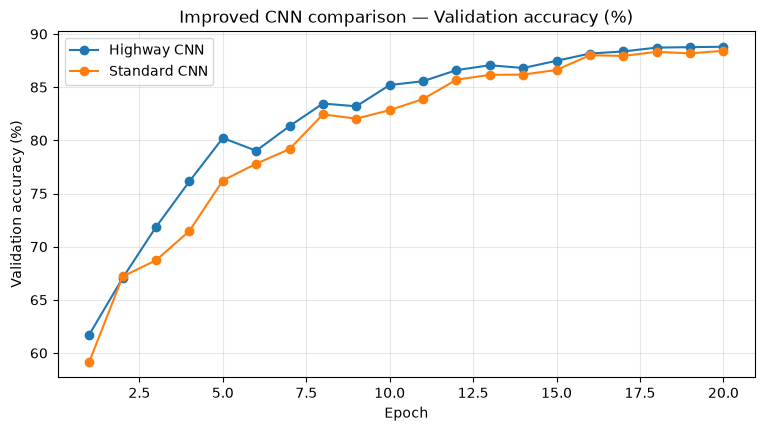

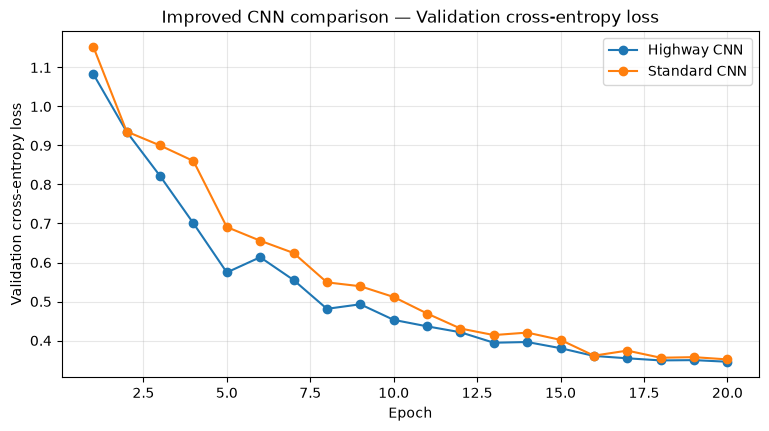

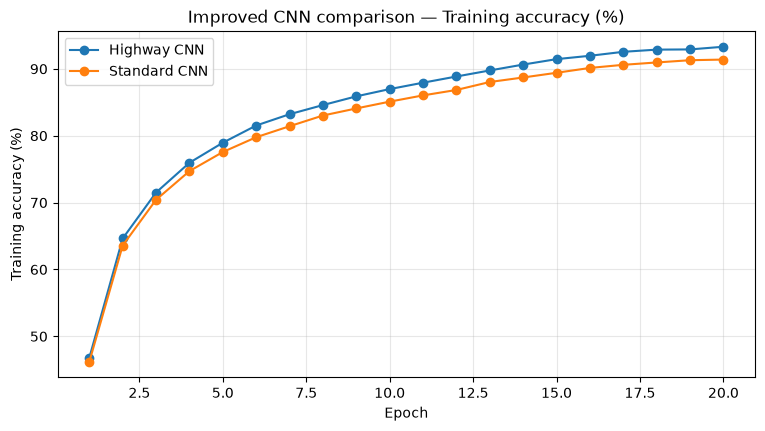

In [10]:
for metric, ylabel in (("val_accuracy", "Validation accuracy (%)"),
                       ("val_loss", "Validation cross-entropy loss"),
                       ("train_accuracy", "Training accuracy (%)")):
    plt.figure(figsize=(9, 4.5))
    plt.plot(range(1, len(highway_history[metric]) + 1),
             highway_history[metric], marker="o", label="Highway CNN")
    plt.plot(range(1, len(standard_history[metric]) + 1),
             standard_history[metric], marker="o", label="Standard CNN")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"Improved CNN comparison — {ylabel}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


## Final Model Comparison — Results and Conclusions

### 1. Experimental Objective

The goal was to investigate whether Highway gates improve CIFAR-10 classification performance compared with conventional convolutional blocks in a stronger, multi-stage architecture.

We compared:

- Improved Highway CNN using convolutional Highway blocks.
- Improved Standard CNN using conventional convolutional blocks.

Both models used the same data split, augmentation, optimizer configuration, learning-rate schedule, and 20-epoch training budget.

### 2. Experimental Results

| Metric | Highway CNN | Standard CNN |
|---|---:|---:|
| Trainable parameters | 870,250 | 482,730 |
| Final training accuracy | 93.30% | 91.39% |
| Best validation accuracy | **88.80%** | 88.42% |
| Selected validation loss | **0.3456** | 0.3515 |
| Best validation epoch | 20 | 20 |
| Training time | 18.5 min | 9.0 min |

The validation accuracy difference was:

$$
\Delta A = 88.80\% - 88.42\%
$$

$$
\boxed{\Delta A = 0.38\text{ percentage points}}
$$

### 3. Observations

1. **Both models achieved similar classification accuracy.**

   The Highway CNN finished with 88.80% validation accuracy, compared with 88.42% for the Standard CNN.

2. **Highway gates provided only a small accuracy advantage.**

   The final difference was 0.38 percentage points.

3. **The Highway CNN required more parameters.**

   The Highway CNN contained 870,250 parameters compared with 482,730 for the Standard CNN.

4. **The Standard CNN trained faster.**

   Training took approximately 9.0 minutes for the Standard CNN and 18.5 minutes for the Highway CNN.

5. **The stronger architecture benefited both models.**

   Multi-stage feature extraction, downsampling, normalization, data augmentation, and learning-rate scheduling enabled both models to reach high validation accuracy.

### 4. Connection to the Depth Experiments

Our earlier depth experiment produced a substantially different result at 50 internal blocks:

| Model | Validation accuracy |
|---|---:|
| Standard CNN, 50 blocks | 10.34% |
| Highway CNN, 50 blocks | 66.06% |

The Standard CNN was unable to optimize successfully under the tested conditions, while the Highway CNN learned useful representations.

At 100 blocks, both architectures experienced optimization difficulties. The Highway CNN showed temporary learning but suffered instability.

These findings suggest that Highway connections may provide greater benefits when optimization becomes difficult due to network depth.

### 5. Limitations

- The architectures have different parameter counts.
- Each comparison used a single random seed.
- The experiments do not isolate gating from differences in model capacity.
- The models are simplified implementations rather than exact reproductions of the original paper.
- Longer training and additional controlled experiments could change the results.

### 6. Final Conclusion

Our experiments demonstrate that Highway Networks can be successfully implemented, trained, and evaluated on CIFAR-10.

The improved Highway CNN achieved:

$$
\boxed{\text{Validation accuracy}=88.80\%}
$$

$$
\boxed{\text{Test accuracy}=88.07\%}
$$

The improved Standard CNN achieved:

$$
\boxed{\text{Validation accuracy}=88.42\%}
$$

The classification performance of the two improved architectures was very similar.

However, the earlier depth experiments showed a much stronger difference in optimization behavior at 50 blocks.

**Overall conclusion:**

Highway Networks are particularly interesting because of their learned information-preserving paths, which can facilitate optimization in deep architectures.

Our experiments suggest that their primary benefit is not necessarily a large accuracy improvement in relatively shallow, well-designed CNNs, but improved trainability as network depth increases.
